# Distribution of predicted ratings (test set, final model)

Final model: single split (no folds), CT + box mask input, class-weighted cross-entropy loss (`train_no_fold.py --mask --loss weighted`), runs in `runs/cls_no_fold_mask_weighted`. Each model's class weights come from its own training targets: model A from the median ratings, model B (retrained) from the readers' shares. Figures are saved in `results/test_no_fold_mask_redoweights`.

How many of the 290 test nodules models A and B assign to each rating, next to the true (median) ratings.
Each model is shown as the mean over seeds 1-3. The predicted rating is the rating with the highest probability.

In [6]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()
sys.path.insert(0, str(PROJECT / "Model"))       # plots.py
sys.path.insert(0, str(PROJECT / "pipeline"))    # metrics.py

RUNS_DIR = PROJECT / "runs" / "cls_no_fold_mask_weighted"
OUT_DIR = PROJECT / "results" / "test_no_fold_mask_redoweights"   # saved next to the other test results of this model
SEEDS = [1, 2, 3]
RATINGS = [1, 2, 3, 4, 5]
P_COLS = [f"p{k}" for k in RATINGS]
KINDS = {"hard": "A", "soft": "B"}

# check these are the final model's runs: CT + mask input, class-weighted loss
for kind in KINDS:
    for s in SEEDS:
        cfg = json.loads((RUNS_DIR / f"{kind}_seed{s}" / "config.json").read_text())
        assert cfg.get("mask") and cfg.get("loss") == "weighted", f"{kind}_seed{s} is not a mask + weighted run"
        if kind == "soft":     # the redone model B: class weights from the readers' shares, not the median ratings
            assert cfg.get("weights_from") == "readers' shares", f"soft_seed{s} still has the old median-rating weights"

labels = pd.read_csv(PROJECT / "data" / "nodules_labels.csv")
test = labels[labels["split"] == "test"].set_index("nodule_key")
hard = test["hard"].to_numpy()
print(f"{len(test)} test nodules")

def probs_of(run):
    """One run's test probabilities, rows in the order of the test nodules."""
    preds = pd.read_csv(RUNS_DIR / run / "test_preds.csv").set_index("nodule_key")
    return preds.loc[test.index, P_COLS].to_numpy()

290 test nodules


## Count the predicted ratings of every run

In [7]:
def count(probs):
    """How many nodules get each rating 1-5 (the rating with the highest probability)."""
    predicted = probs.argmax(axis=1) + 1
    return np.array([(predicted == r).sum() for r in RATINGS])

# one count per seed: rows = seeds, columns = ratings 1-5
groups = {f"Model {m}": np.array([count(probs_of(f"{kind}_seed{s}")) for s in SEEDS]) for kind, m in KINDS.items()}
true_counts = np.array([(test["hard"] == r).sum() for r in RATINGS])

## Table (mean ± SD)

SD is the sample standard deviation over the 3 seeds (the same as `summary.csv`).

In [8]:
rows = {"True (median rating)": [str(c) for c in true_counts]}
for name, runs in groups.items():
    rows[name] = [f"{m:.1f} ± {s:.1f}" for m, s in zip(runs.mean(axis=0), runs.std(axis=0, ddof=1))]

table = pd.DataFrame(rows, index=[f"Rating {r}" for r in RATINGS]).T
table

,Rating 1,Rating 2,Rating 3,Rating 4,Rating 5
True (median rating),37,46,136,44,27
Model A,37.7 ± 1.5,23.3 ± 9.6,155.0 ± 14.7,42.3 ± 6.5,31.7 ± 1.5
Model B,43.0 ± 2.6,50.0 ± 1.0,123.7 ± 2.3,26.7 ± 5.7,46.7 ± 3.2


## Bar chart

Bars are the mean over the 3 seeds; error bars run from the lowest to the highest seed, so they can't go below 0.

In [9]:
def bars(names, colours, title):
    series = [("True (median rating)", true_counts[None, :], "0.6")] + \
             [(n, groups[n], c) for n, c in zip(names, colours)]
    width = 0.8 / len(series)
    x = np.arange(len(RATINGS))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i, (name, runs, colour) in enumerate(series):
        mean = runs.mean(axis=0)
        # error bar = lowest to highest run, as distances below and above the mean
        err = np.vstack([mean - runs.min(axis=0), runs.max(axis=0) - mean]) if len(runs) > 1 else None
        ax.bar(x + (i - (len(series) - 1) / 2) * width, mean, width, yerr=err, capsize=3,
               color=colour, label=name, error_kw={"elinewidth": 1})
    ax.set_xticks(x, [str(r) for r in RATINGS])
    ax.set_xlabel("rating")
    ax.set_ylabel("number of test nodules")
    ax.set_ylim(0, 1.1 * max(true_counts.max(), max(groups[n].max() for n in names)))
    ax.set_title(title, fontsize=11)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()

## No folds

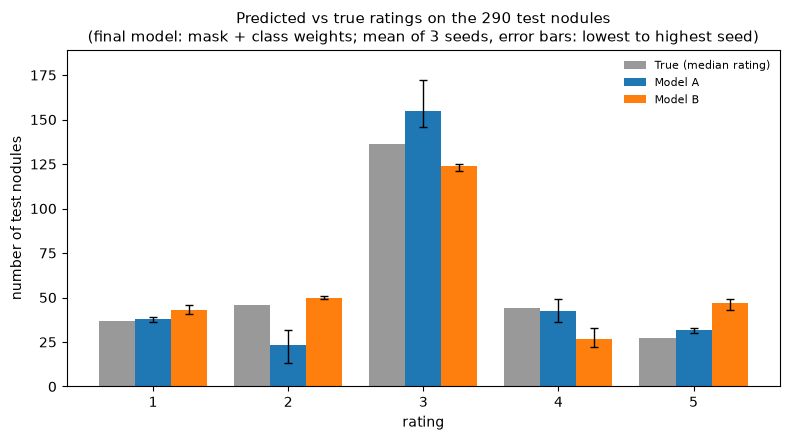

In [10]:
bars(["Model A", "Model B"], ["tab:blue", "tab:orange"],
     "Predicted vs true ratings on the 290 test nodules\n"
     "(final model: mask + class weights; mean of 3 seeds, error bars: lowest to highest seed)")